findfont: Failed to find font weight light for Montserrat, now using 300.
findfont: Failed to find font weight light for Montserrat, now using 300.
findfont: Failed to find font weight light for Montserrat, now using 300.


saved ne_basins.png (2577, 2949)


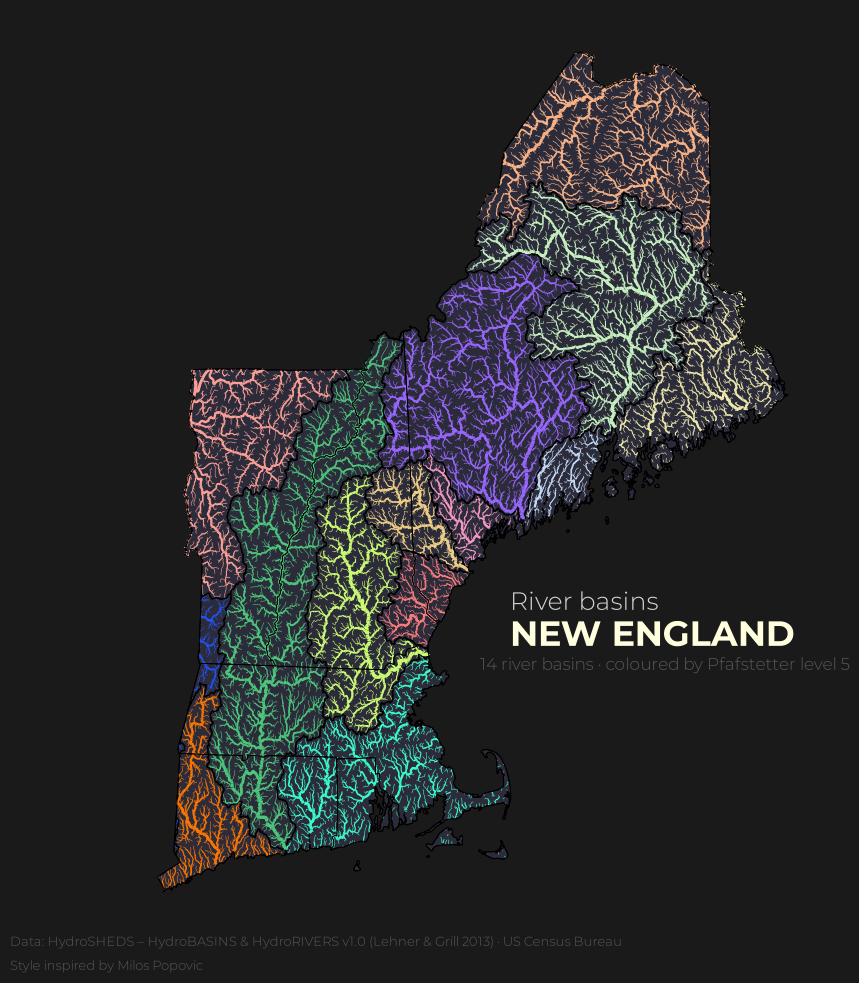

In [70]:
import geopandas as gpd
from matplotlib.colors import ListedColormap
import pandas as pd
import matplotlib.pyplot as plt
import io
from PIL import Image
from pathlib import Path
from matplotlib import font_manager

font_manager.fontManager.addfont(
    "Fonts/Montserrat-Bold.ttf"
)
font_manager.fontManager.addfont(
    "Fonts/Montserrat-Light.ttf"
)


west_newE = -(73 + 43/60 + 39/3600)
east_newE = -(66 + 56/60 + 59/3600) 
south_newE = (40 + 59/60 + 0/3600)
north_newE = (47 + 27/60 + 35/3600)

ne_box = (west_newE, south_newE, east_newE, north_newE)
#print(ne_box)


basins_path = "data/hybas_na_lev01-12_v1c/hybas_na_lev12_v1c.shp"#given the path to the shapefile, read it into a GeoDataFrame and clip it to the bounding box of New England
basins = gpd.read_file(basins_path, bbox=ne_box)#given the path to the shapefile, read it into a GeoDataFrame and clip it to the bounding box of New England
rivers_path = "../03-rivers/data/HydroRIVERS_v10_na_shp"#given the path to the shapefile, read it into a GeoDataFrame and clip it to the bounding box of New England
rivers = gpd.read_file(rivers_path, bbox=ne_box)
#print(len(rivers))
#print(len(basins))
#print(rivers.columns)
#print(basins.columns)
#print(basins["HYBAS_ID"])
#print(basins["PFAF_ID"])
merged = pd.merge(rivers, basins[["HYBAS_ID", "PFAF_ID"]], left_on="HYBAS_L12", right_on="HYBAS_ID",how="left")
#print(merged.columns)
#print(len(merged))
#NaN_count = merged["PFAF_ID"].isna().sum()
#print(f"Number of NaN values in PFAF_ID: {NaN_count}")
#type(merged) this is a GeoDataFrame
states_path = "../03-rivers/data/cb_2025_us_state_5m"
state = gpd.read_file(states_path)
ne_states = state[state["STUSPS"].isin(["MA","RI","NH","ME","CT","VT"])]
ne_states = ne_states.to_crs(basins.crs)
#ne_states.plot()
#print(basins.crs)
#print(ne_states.crs)
ne_rivers_basins = gpd.clip(merged, ne_states)
#print(len(ne_rivers_basins))
ne_rivers_basins["PFAF_ID"] = ne_rivers_basins["PFAF_ID"].astype("string")
ne_rivers_basins["PFAF_L5"] = ne_rivers_basins["PFAF_ID"].str[:5]
#print(len(ne_rivers_basins["PFAF_L5"].unique()))

basins_path_lv5 = "data/hybas_na_lev01-12_v1c/hybas_na_lev05_v1c.shp"
basins_lv5 = gpd.read_file(basins_path_lv5)
ne_basins_lv5 = gpd.clip(basins_lv5, ne_states)
ne_basins_lv5["PFAF_ID"] = ne_basins_lv5["PFAF_ID"].astype("string")
missing_basins = ne_basins_lv5[~ne_basins_lv5["PFAF_ID"].isin(ne_rivers_basins["PFAF_L5"])]#this is to find the basins that are in the basins dataset but not in the rivers dataset
ne_basins_lv5_final = ne_basins_lv5[ne_basins_lv5["PFAF_ID"].isin(ne_rivers_basins["PFAF_L5"])]#this is to find the basins that are in the basins dataset and in the rivers dataset
#print(len(ne_basins_lv5))
#print(len(basins_lv5))
#print(len(missing_basins))
#ne_basins_lv5.plot()
#print(missing_basins ["PFAF_ID"].unique())
#print(missing_basins ["SUB_AREA"].unique())
#print(missing_basins ["HYBAS_ID"].unique())
#print (ne_rivers_basins.columns) 
fig, ax = plt.subplots(figsize=(10, 12))
ax.set_axis_off()
my_colors = ['#fba097', "#f8b287", '#ece7ac', '#c6efbf', '#c4dbf7', "#9766faff", "#f599c2","#edce87",  "#f67d7d", "#caf973", "#3bfbcb", "#4dc57b", "#f97603", "#2253f5"]
# a palette of colors for the basins
my_cmap = ListedColormap(my_colors)
fig.set_facecolor("#1a1a1a")
ax.set_facecolor("#1a1a1a")
#missing_basins.plot(color="red", edgecolor="red", linewidth=1, ax=ax)/ this is to show the missing basins in red
ne_states.plot(color="#2b2b3a", linewidth=0.3, ax=ax)
ne_basins_lv5_final.boundary.plot(color="black", linewidth=0.8, ax=ax)
ne_rivers_basins.plot(column="PFAF_L5", cmap=my_cmap, linewidth=ne_rivers_basins["ORD_STRA"]*0.4, categorical=True, ax=ax)
ne_states.boundary.plot(color="black", linewidth=0.6, ax=ax)
fig.text(0.55, 0.38, "River basins", color="lightgray", fontfamily="Montserrat", fontweight="light", fontsize=18)
fig.text(0.55, 0.35, "NEW ENGLAND", color="lightyellow", fontfamily="Montserrat", fontweight="bold",fontsize=25)
fig.text(0.05, 0.1, "Data: HydroSHEDS – HydroBASINS & HydroRIVERS v1.0 (Lehner & Grill 2013) · US Census Bureau", color="#585757", fontfamily="Montserrat", fontweight="light", fontsize=9)
fig.text(0.05, 0.08, "Style inspired by Milos Popovic", color="#585757", fontfamily="Montserrat", fontweight="light", fontsize=9)
fig.text(0.52, 0.33, "14 river basins · coloured by Pfafstetter level 5", color="#585757", fontfamily="Montserrat", fontweight="light", fontsize=12)

def save_clean_png(fig, path, dpi=200):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight", facecolor="#1a1a1a")
    buf.seek(0)
    img = Image.open(buf)
    Image.frombytes(img.mode, img.size, img.tobytes()).save(path, "PNG", optimize=True)
    print("saved", path, img.size)

save_clean_png(fig, "ne_basins.png", dpi=300)
